In [67]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [68]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pickle

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.inference.posteriors import DirectPosterior

# Posterior Inference Evaluation

Posterior sampling and analysis for trained neural density estimator.

In [69]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from simulator import smFRET_simulator_wrapper_from_config
from priors import generate_posterior_prior_from_config
from utils import eval_free_energy_from_config

## 1. Setup: Imports and Configurations

In [70]:
import yaml

outputs_root = project_root / "outputs"

run_selector = "latest"
# Example explicit selector:
run_selector = "exp_1/18-50-44/"
#run_selector = "base/2026-03-17/18-37-45"
#run_selector = "2026-03-12/18-34-42"


def resolve_run_dir(selector: str) -> Path:
    if selector != "latest":
        candidate = (outputs_root / selector).resolve()
        if not candidate.exists():
            raise FileNotFoundError(f"Run directory not found: {candidate}")
        return candidate

    model_candidates = list(outputs_root.rglob("density_estimator.pkl"))
    if not model_candidates:
        raise FileNotFoundError(f"No trained model found below {outputs_root}")
    return max(model_candidates, key=lambda p: p.stat().st_mtime).parent


def load_hydra_cfg(run_dir: Path) -> dict:
    hydra_cfg_path = run_dir / ".hydra" / "config.yaml"
    if not hydra_cfg_path.exists():
        return {}
    return yaml.safe_load(hydra_cfg_path.read_text())


def resolve_data_config(run_dir: Path, hydra_cfg: dict) -> Path:
    copied = run_dir / "data_config.yaml"
    if copied.exists():
        return copied

    data_dir_rel = hydra_cfg.get("data", {}).get("data_dir")
    if data_dir_rel is None:
        raise FileNotFoundError(
            f"Could not resolve data config: missing {copied} and data.data_dir in .hydra/config.yaml"
        )

    fallback = (project_root / data_dir_rel / "config.yaml").resolve()
    if not fallback.exists():
        raise FileNotFoundError(f"Data config not found: {fallback}")
    return fallback


def resolve_model_path(run_dir: Path, hydra_cfg: dict) -> Path:
    model_filename = hydra_cfg.get("artifacts", {}).get("model_filename", "density_estimator.pkl")
    model_path = run_dir / model_filename
    if not model_path.exists():
        raise FileNotFoundError(f"Model file not found: {model_path}")
    return model_path


run_dir = resolve_run_dir(run_selector)
hydra_cfg = load_hydra_cfg(run_dir)
data_cfg = resolve_data_config(run_dir, hydra_cfg)
model_path = resolve_model_path(run_dir, hydra_cfg)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"run_dir  : {run_dir}")
print(f"data_cfg : {data_cfg}")
print(f"model    : {model_path}")
print(f"device   : {device}")

run_dir  : /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/exp_1/18-50-44
data_cfg : /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/exp_1/18-50-44/data_config.yaml
model    : /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/exp_1/18-50-44/ratio_estimator.pkl
device   : cuda


## 2. Load Trained Model and Select Run

In [71]:
prior = generate_posterior_prior_from_config(str(data_cfg), device=device)
eval_free_energy = eval_free_energy_from_config(str(data_cfg))

## 3. Initialize Prior and Simulator

In [72]:
# ============================================================================
# Sampling and Optimization Configuration
# ============================================================================

config = {
    # Posterior sampling
    "num_posterior_samples": 10000,
    "posterior_batch_size": 1000,
    
    # Log-prob batching (to avoid OOM)
    "log_prob_batch_size": 500,
    
    # MAP estimation
    "map_num_iter": 500,
    "map_num_to_optimize": 1,
    "map_learning_rate": 0.01,
    "map_init_method": "posterior",
    "map_num_init_samples": 5,
    "map_save_best_every": 10,
    "map_show_progress_bars": False,
    "map_force_update": False,
}

In [73]:
def bin_along_time(x, n_bins=100):
    n = len(x)
    n_per_bin = int(n / n_bins)
    x_binned = np.zeros(n_bins)
    for i in range(n_bins):
        x_binned[i] = np.sum(x[i*n_per_bin:(i+1)*n_per_bin])
    return x_binned

In [74]:
fret_simulator = smFRET_simulator_wrapper_from_config(str(data_cfg))

In [98]:
true_params = torch.tensor([0.1, -.4, -0.5, -0.5, 0.2, 0.2, 1.0,  6, 8.00, 0.0100,  0.01000,  0.9500,  0.9500,  0.9000,  0.9000,  0.1000,  0.1000], dtype=torch.float64)

(0.0, 7.0)

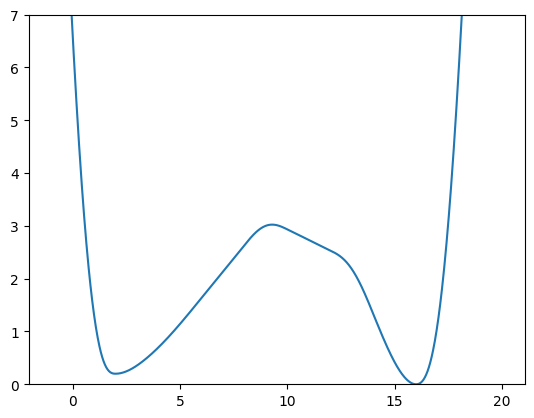

In [99]:
x, y = eval_free_energy(
    params=true_params,
    x_eval=np.linspace(-1, 20, 1000),
)
plt.plot(x, y - y.min(), label='Ground Truth')
plt.ylim(0, 7)

In [100]:
observation = torch.stack([fret_simulator(true_params) for _ in range(1)])

## 4. Create Test Observation

Text(0.5, 0, 'Time')

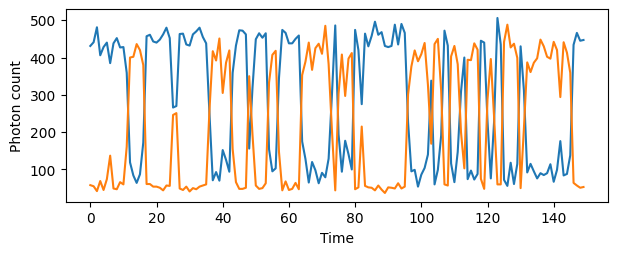

In [101]:
idx = 0
plt.figure(figsize=(7, 2.5))
plt.plot(bin_along_time(observation[idx, :,0].numpy(), n_bins=150), label="Donor")
plt.plot(bin_along_time(observation[idx, :,1].numpy(), n_bins=150), label="acceptor")
plt.ylabel("Photon count")
plt.xlabel("Time")

In [102]:
with open(model_path, "rb") as f:
    density_estimator = pickle.load(f)
density_estimator = density_estimator.to(device)

In [103]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Number of parameters in the density estimator: {count_parameters(density_estimator)}")

Number of parameters in the density estimator: 11803841


## 5. Posterior Inference

In [104]:
posterior = DirectPosterior(density_estimator, prior=prior)
obs = observation.to(device)
samples = posterior.sample(
    (config["num_posterior_samples"],),
    x=obs,
    max_sampling_batch_size=config["posterior_batch_size"]
).cpu()

# Batch log_prob computation to avoid OOM
log_probs_list = []
for i in range(0, samples.shape[0], config["log_prob_batch_size"]):
    batch = samples[i:i+config["log_prob_batch_size"]].to(device)
    log_probs_list.append(
        posterior.log_prob_batched(batch, x=obs, norm_posterior=False).cpu()
    )
log_probs = torch.cat(log_probs_list)

10151it [00:00, 19589.99it/s]                          


In [105]:
posterior.set_default_x(observation.to(device))
map_estimate = posterior.map(
    num_iter=100,
    num_to_optimize=config["map_num_to_optimize"],
    learning_rate=config["map_learning_rate"],
    init_method=config["map_init_method"],
    num_init_samples=config["map_num_init_samples"],
    save_best_every=config["map_save_best_every"],
    show_progress_bars=True,
    force_update=True,
)

100%|██████████| 5/5 [00:00<00:00, 105.27it/s]


 Optimizing MAP estimate. Iterations: 100 / 100. Performance in iteration 100: 6.63 (= unnormalized log-prob). Press Ctrl-C to interrupt.

/tmp/ipykernel_2094069/1374595667.py:1: DeprecationWarning: you passed deprecated arguments **kwargs: ['points_offdiag', 'points_colors'], use fig_kwargs instead. We continue calling the deprecated pairplot function
  _ = analysis.pairplot(


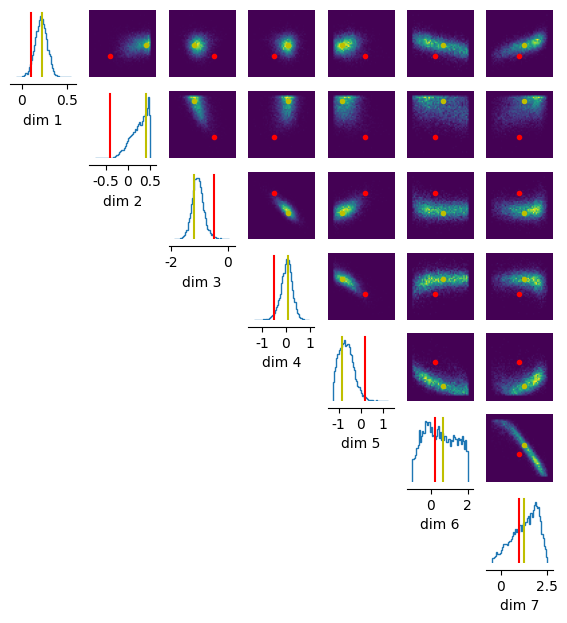

In [106]:
_ = analysis.pairplot(
    samples,
    figsize=(7,7),
    points=[true_params, map_estimate[0].cpu()], 
    points_offdiag={'markersize': 6},
    points_colors=['r', 'y'], 
)

## 6. Analyze Results

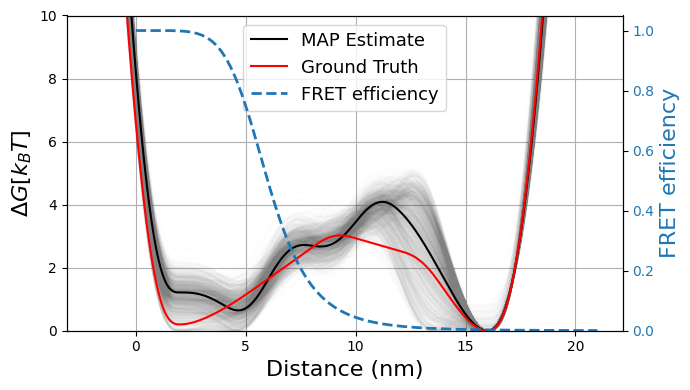

In [107]:
x_min, x_max = -2, 21
x_eval = np.linspace(x_min, x_max, 1000)

fig, ax1 = plt.subplots(figsize=(7, 4))

# Free-energy samples
for i in range(1000):
    x, y = eval_free_energy(
        params=samples[i],
        x_eval=x_eval,
    )
    ax1.plot(x, y - y.min(), color="gray", alpha=0.01)

# MAP free-energy
x, y = eval_free_energy(
    params=map_estimate[0].cpu(),
    x_eval=x_eval,
)
ax1.plot(x, y - y.min(), color="black", label="MAP Estimate")

# Ground-truth free-energy
x, y = eval_free_energy(
    params=true_params,
    x_eval=x_eval,
)
ax1.plot(x, y - y.min(), color="r", label="Ground Truth")

ax1.set_xlabel("Distance (nm)", fontsize=16)
ax1.set_ylabel(r"$\Delta G [k_{B}T]$", fontsize=16)
ax1.set_ylim(0, 10)
ax1.grid()

# Secondary axis: FRET efficiency
ax2 = ax1.twinx()
R0 = float(true_params[7])  # uses your existing parameter vector
r = np.clip(x_eval, 1e-9, None)
E = 1.0 / (1.0 + (r / R0) ** 6)
E[x_eval <= 0] = np.nan  # hide non-physical negative distances

ax2.plot(x_eval, E, color="tab:blue", linestyle="--", linewidth=2, label="FRET efficiency")
ax2.set_ylabel("FRET efficiency", color="tab:blue", fontsize=16)
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis="y", labelcolor="tab:blue")

# Combined legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=13, loc="best")

plt.tight_layout()

Text(0, 0.5, 'p(log(D)|x)')

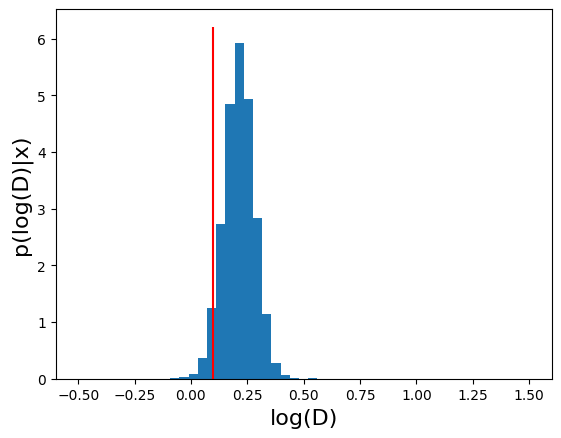

In [108]:
plt.hist(samples[:, 0].numpy(), bins=np.linspace(-0.5, 1.5, 50), density=True)
plt.vlines(true_params[0], ymin=0, ymax=plt.gca().get_ylim()[1], color='r', label='Ground Truth')
plt.xlabel("log(D)", fontsize=16)
plt.ylabel("p(log(D)|x)", fontsize=16)